## The question

A common claim in climate policy is that richer countries emit more carbon per person, up to a point, after which growth and emissions come apart. Grossman and Krueger (1995) gave the idea its best known form, the **environmental Kuznets curve**: pollution rises with income at first and falls once a country is rich enough. This notebook tests the simplest version of that claim on one year of cross-country data. The question is how closely CO2 emissions per person follow GDP per person in 2022, and whether the richest countries break from the pattern.

## Data

The data are external files downloaded from GitHub, not datasets bundled with seaborn or Plotly.

- **Our World in Data CO2 dataset** (Our World in Data, 2026), from the `owid/co2-data` repository. Emissions are fossil fuel and industrial CO2 in tonnes per person, from the **Global Carbon Budget** (Global Carbon Project, 2026). GDP is in 2011 international dollars, adjusted for prices and living costs, from the **Maddison Project Database 2023** (Bolt and van Zanden, 2024). The codebook is saved next to the data in `data/`.
- **ISO 3166 regional codes** (Lukes, 2024), from the `lukes/ISO-3166-Countries-with-Regional-Codes` repository. It assigns each country a UN region and subregion.

2022 is the latest year with GDP figures in the dataset. Both variables enter the model in base 10 logs, for two reasons. Income and emissions each span three orders of magnitude (from under $1,000 to over $100,000 per person), so on a linear scale a handful of rich countries would dominate the fit. And in logs the slope reads as an **elasticity**: the percentage change in emissions that goes with a 1 percent change in income.

In [1]:
#| label: setup
#| code-fold: false
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
import altair as alt
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook_connected"
alt.renderers.enable("html", template="inline")

RendererRegistry.enable('html')

In [2]:
#| label: load-data
os.makedirs("data", exist_ok=True)
files = {}
files["data/owid-co2-data.csv"] = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"
files["data/iso_regions.csv"] = "https://raw.githubusercontent.com/lukes/ISO-3166-Countries-with-Regional-Codes/master/all/all.csv"
for path, url in files.items():
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
owid = pd.read_csv("data/owid-co2-data.csv")
iso = pd.read_csv("data/iso_regions.csv")
countries = owid[(owid["year"] == 2022) & owid["iso_code"].notna() & ~owid["iso_code"].str.startswith("OWID", na=False)]
df = countries.merge(iso[["alpha-3", "region", "sub-region"]], left_on="iso_code", right_on="alpha-3", how="left")
print("Countries in 2022:", len(df))
print("Without an ISO region:", df.loc[df["region"].isna(), "country"].tolist())
df["gdp_pc"] = df["gdp"] / df["population"]
df = df[df["gdp_pc"].notna() & (df["co2_per_capita"] > 0)].copy()
df["region"] = df["region"].fillna("Asia")
df["log_gdp_pc"] = np.log10(df["gdp_pc"])
df["log_co2_pc"] = np.log10(df["co2_per_capita"])
df["log_energy_pc"] = np.log10(df["energy_per_capita"])
df["coal_share"] = 100 * df["coal_co2"] / df["co2"]
df["oil_share"] = 100 * df["oil_co2"] / df["co2"]
print("Countries with GDP and CO2:", len(df))

Countries in 2022: 223
Without an ISO region: ['Antarctica', 'Taiwan']
Countries with GDP and CO2: 164


The join on ISO alpha-3 codes left two places without a region: Antarctica, which has no GDP and drops out, and Taiwan, which the ISO table lists without a region. Taiwan is assigned to Asia by hand, which is the only manual step in the pipeline. The final sample is **164 countries**.

In [3]:
#| label: colours
region_colors = {"Africa": "darkorange", "Americas": "royalblue", "Asia": "orchid", "Europe": "mediumseagreen", "Oceania": "black"}
regions = list(region_colors)
gdp_ticks = [3, 4, 5]
gdp_labels = ["$1,000", "$10,000", "$100,000"]
co2_ticks = [-1, 0, 1]
co2_labels = ["0.1 t", "1 t", "10 t"]
morocco = df[df["iso_code"] == "MAR"].iloc[0]

## Regression fit and confidence interval

The model is an ordinary least squares regression of log CO2 per person on log GDP per person.

In [4]:
#| label: model
model = smf.ols("log_co2_pc ~ log_gdp_pc", data=df).fit()
df["fitted"] = model.fittedvalues
df["residual"] = model.resid
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             log_co2_pc   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.830
Method:                 Least Squares   F-statistic:                     794.7
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           2.30e-64
Time:                        22:09:07   Log-Likelihood:                -5.4115
No. Observations:                 164   AIC:                             14.82
Df Residuals:                     162   BIC:                             21.02
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.8884      0.151    -25.794      0.0

In [5]:
#| label: model-numbers
low, high = model.conf_int().loc["log_gdp_pc"]
print(f"Elasticity: {model.params['log_gdp_pc']:.3f} (95% CI {low:.3f} to {high:.3f})")
print(f"R squared: {model.rsquared:.3f}")
print(f"Residual standard error: {np.sqrt(model.scale):.3f} log10 units, a factor of {10 ** np.sqrt(model.scale):.2f}")
print(f"Shapiro-Wilk test of residual normality: p = {stats.shapiro(model.resid).pvalue:.3f}")

Elasticity: 1.048 (95% CI 0.974 to 1.121)
R squared: 0.831
Residual standard error: 0.252 log10 units, a factor of 1.78
Shapiro-Wilk test of residual normality: p = 0.080


The slope is **1.048**, and its 95 percent confidence interval (0.974 to 1.121) contains 1. A 10 percent richer country emits, on average, about 10 percent more CO2 per person, so emissions per person and income per person rise in proportion. Income alone accounts for 83 percent of the cross-country variation. The residual standard error (0.25 in log10 units) means a typical country sits within a factor of about 1.8 of the line, which is the spread the residual plot examines below.

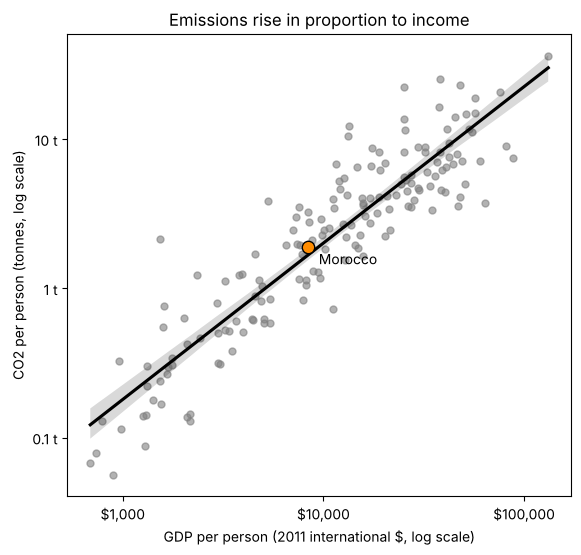

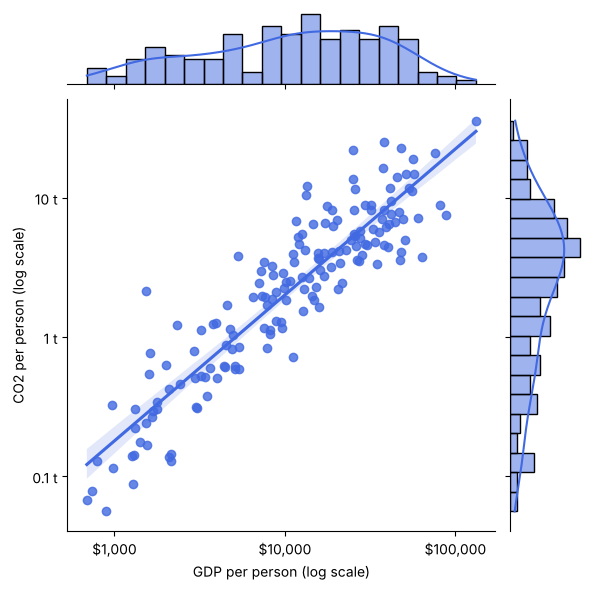

In [6]:
#| label: fig-regression
#| fig-cap: "Regression of CO2 per person on GDP per person, 164 countries, 2022, both axes on log scales. Left: seaborn regplot with the OLS line and its 95 percent confidence band. Right: seaborn jointplot with the same fit and the marginal distributions of each variable. Sources: Global Carbon Project (2026); Bolt and van Zanden (2024), via Our World in Data (2026)."
#| fig-subcap:
#|   - "regplot"
#|   - "jointplot"
#| layout-ncol: 2
fig, ax = plt.subplots(figsize=(6.5, 6))
sns.regplot(data=df, x="log_gdp_pc", y="log_co2_pc", ci=95, scatter_kws={"s": 25, "color": "grey", "alpha": 0.6}, line_kws={"color": "black"}, ax=ax)
ax.scatter(morocco["log_gdp_pc"], morocco["log_co2_pc"], s=80, color="darkorange", edgecolor="black", zorder=3)
ax.annotate("Morocco", (morocco["log_gdp_pc"], morocco["log_co2_pc"]), xytext=(8, -12), textcoords="offset points")
ax.set_xticks(gdp_ticks)
ax.set_xticklabels(gdp_labels)
ax.set_yticks(co2_ticks)
ax.set_yticklabels(co2_labels)
ax.set_xlabel("GDP per person (2011 international $, log scale)")
ax.set_ylabel("CO2 per person (tonnes, log scale)")
ax.set_title("Emissions rise in proportion to income")
plt.show()
grid = sns.jointplot(data=df, x="log_gdp_pc", y="log_co2_pc", kind="reg", color="royalblue", height=6, marginal_kws={"bins": 20})
grid.ax_joint.set_xticks(gdp_ticks)
grid.ax_joint.set_xticklabels(gdp_labels)
grid.ax_joint.set_yticks(co2_ticks)
grid.ax_joint.set_yticklabels(co2_labels)
grid.set_axis_labels("GDP per person (log scale)", "CO2 per person (log scale)")
plt.show()

The confidence band is narrow in the middle of the income range and widens at both ends, where there are fewer countries. The jointplot margins add one thing the regplot hides: in logs both variables are close to symmetric, which is part of why the log transformation suits this model. Morocco sits almost on the line, at about $8,300 GDP and 1.9 tonnes of CO2 per person.

## Correlation matrix

The heatmap places the two model variables among five others from the same dataset: energy use per person, the **carbon intensity of energy** (grams of CO2 per kilowatt hour), the shares of CO2 from coal and from oil, and the model's own residual. Including the residual shows which of these variables track what income leaves unexplained.

In [7]:
#| label: correlations
heat_columns = {"log_gdp_pc": "GDP per person (log)", "log_co2_pc": "CO2 per person (log)", "log_energy_pc": "Energy per person (log)", "co2_per_unit_energy": "CO2 per kWh of energy", "coal_share": "Coal share of CO2", "oil_share": "Oil share of CO2", "residual": "Model residual"}
corr = df[list(heat_columns)].rename(columns=heat_columns).corr()
print("Countries with a coal share:", df["coal_share"].notna().sum(), "of", len(df))

Countries with a coal share: 129 of 164


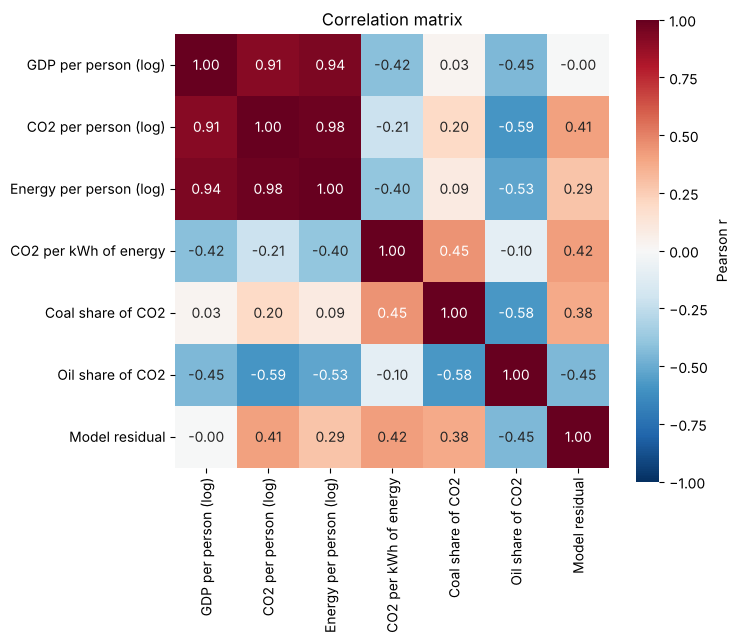

In [8]:
#| label: fig-heatmap
#| fig-cap: "Pearson correlations among seven country variables, 2022. Pairs use every country with both values; the coal share is missing for 35 countries with no recorded coal emissions. Left: static seaborn heatmap. Right: interactive Plotly heatmap with the exact coefficient on hover."
#| layout-ncol: 2
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix")
plt.show()
heat = px.imshow(corr.round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto", title="Correlation matrix (hover for values)")
heat.update_layout(height=520, margin={"l": 10, "r": 10, "t": 50, "b": 10})
heat.show()

Energy use per person correlates with CO2 per person at 0.98, more tightly than income does (0.91). Income works through energy: richer countries use more of it, and most of that energy is still fossil. The residual column shows the remaining variation. It correlates at 0.42 with carbon intensity and at 0.38 with the coal share. Countries above the line burn dirtier energy for their income level, not just more of it.

## Residuals

A residual is the gap between a country's actual log emissions and the value the model predicts from its income. A residual of +0.3 means about twice the predicted emissions; -0.3 means about half.

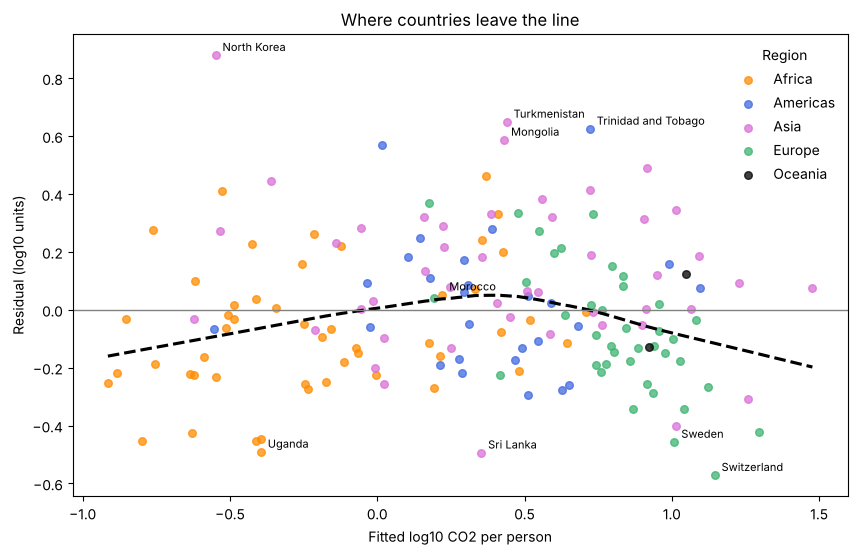

In [9]:
#| label: fig-residuals
#| fig-cap: "Residuals against fitted values, coloured by region. The dashed black curve is a LOWESS smoother through the residuals; a well specified model would keep it flat at zero. The eight countries furthest from the line and Morocco are labelled."
fig, ax = plt.subplots(figsize=(10, 6))
for region, color in region_colors.items():
    part = df[df["region"] == region]
    ax.scatter(part["fitted"], part["residual"], s=30, color=color, alpha=0.75, label=region)
sns.regplot(data=df, x="fitted", y="residual", lowess=True, scatter=False, line_kws={"color": "black", "linestyle": "--"}, ax=ax)
ax.axhline(0, color="grey", linewidth=1)
extremes = pd.concat([df.nsmallest(4, "residual"), df.nlargest(4, "residual"), df[df["iso_code"] == "MAR"]])
for index, row in extremes.iterrows():
    ax.annotate(row["country"], (row["fitted"], row["residual"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Fitted log10 CO2 per person")
ax.set_ylabel("Residual (log10 units)")
ax.set_title("Where countries leave the line")
ax.legend(title="Region", frameon=False)
plt.show()

In [10]:
#| label: residual-groups
print(df.groupby("sub-region")["residual"].agg(["mean", "count"]).sort_values("mean").round(2))

                                 mean  count
sub-region                                  
Northern Europe                 -0.21     10
Western Europe                  -0.20      7
Sub-Saharan Africa              -0.09     45
Southern Asia                   -0.05      7
Southern Europe                 -0.04     12
Australia and New Zealand       -0.00      2
Latin America and the Caribbean  0.02     25
South-eastern Asia               0.05      9
Eastern Europe                   0.10     10
Northern Africa                  0.12      5
Northern America                 0.12      2
Western Asia                     0.15     18
Eastern Asia                     0.25      6
Central Asia                     0.31      5


The residual plot shows no funnel: the spread is about the same at every fitted value, which matches the constant variance assumption of OLS. The labels sort into two groups. Above the line are fossil fuel producers and coal economies: Turkmenistan, Trinidad and Tobago, and Mongolia emit about four times what their income predicts. Below the line are economies that run on hydro or nuclear power (Switzerland, Sweden) and low income economies where most energy still comes from biomass that the CO2 series excludes (Uganda, Rwanda, the Democratic Republic of the Congo). North Korea is the largest residual (+0.88), but its GDP figure is a Maddison estimate for a closed economy, so the outlier says more about the data than about North Korea's energy system.

The LOWESS curve is the one sign of trouble. It sits above zero in the middle of the fitted range and falls below it at both ends. That inverted U suggests the straight line overstates the slope at high and low incomes and understates it in between. The next section tests that curvature directly.

## Testing the curve

A quadratic term in log income tests whether the relationship bends. An environmental Kuznets curve would need the slope to fall to zero and turn negative within the observed income range.

In [11]:
#| label: quadratic
quadratic = smf.ols("log_co2_pc ~ log_gdp_pc + I(log_gdp_pc ** 2)", data=df).fit()
print(quadratic.summary().tables[1])
b1 = quadratic.params["log_gdp_pc"]
b2 = quadratic.params["I(log_gdp_pc ** 2)"]
peak = 10 ** (-b1 / (2 * b2))
print(f"R squared: {model.rsquared:.3f} linear, {quadratic.rsquared:.3f} quadratic")
print(f"Income at which emissions would peak: ${peak:,.0f} per person")
print(f"Richest country in the sample: ${df['gdp_pc'].max():,.0f} per person")
rich = smf.ols("log_co2_pc ~ log_gdp_pc", data=df[df["gdp_pc"] > 30000]).fit()
rest = smf.ols("log_co2_pc ~ log_gdp_pc", data=df[df["gdp_pc"] <= 30000]).fit()
print(f"Slope below $30,000: {rest.params['log_gdp_pc']:.2f} ({len(rest.resid)} countries)")
print(f"Slope above $30,000: {rich.params['log_gdp_pc']:.2f} ({len(rich.resid)} countries)")

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -7.0264      1.009     -6.962      0.000      -9.019      -5.033
log_gdp_pc             2.6768      0.520      5.152      0.000       1.651       3.703
I(log_gdp_pc ** 2)    -0.2074      0.066     -3.143      0.002      -0.338      -0.077
R squared: 0.831 linear, 0.840 quadratic
Income at which emissions would peak: $2,831,609 per person
Richest country in the sample: $131,991 per person
Slope below $30,000: 1.15 (127 countries)
Slope above $30,000: 0.80 (37 countries)


The squared term is negative and significant (p = 0.002), so the curve does bend: the elasticity is about 1.15 among countries below $30,000 per person and about 0.80 among the 37 countries above it. But the implied peak sits at roughly $2.8 million per person, more than 20 times the richest country in the sample. In this cross-section, emissions keep rising with income everywhere; growth slows them but does not reverse them.

## Interactive views

### Connected view in Altair

The Altair chart links three views. Dragging a rectangle on the scatter plot selects a group of countries; the bar chart then shows the mean residual of the selection by region, and the histogram shows the distribution of their residuals. Clicking a region in the legend below the scatter plot highlights that region's countries. The black line is the OLS fit from the model above, converted back from logs, so it is a straight line on the log axes. Double click clears the selection.

In [12]:
#| label: fig-altair
#| fig-cap: "Connected view in Altair. Drag on the scatter plot to select countries; the bar chart and histogram update to the selection. Click a region in the legend to highlight it. Hover any point for its figures."
brush = alt.selection_interval(encodings=["x", "y"])
pick = alt.selection_point(fields=["region"], bind="legend")
color_scale = alt.Scale(domain=regions, range=list(region_colors.values()))
base = alt.Chart(df[["country", "region", "gdp_pc", "co2_per_capita", "residual"]])
points = base.mark_circle(size=60).encode(
    x=alt.X("gdp_pc:Q", scale=alt.Scale(type="log", domain=[500, 200000], nice=False), axis=alt.Axis(values=[1000, 10000, 100000], format="$,.0f"), title="GDP per person (2011 int. $, log scale)"),
    y=alt.Y("co2_per_capita:Q", scale=alt.Scale(type="log", domain=[0.03, 60], nice=False), axis=alt.Axis(values=[0.1, 1, 10]), title="CO2 per person (tonnes, log scale)"),
    color=alt.condition(brush, alt.Color("region:N", scale=color_scale, title="Region (click to highlight)", legend=alt.Legend(orient="bottom")), alt.value("lightgrey")),
    opacity=alt.condition(pick, alt.value(0.9), alt.value(0.1)),
    tooltip=[alt.Tooltip("country:N", title="Country"), alt.Tooltip("region:N", title="Region"), alt.Tooltip("gdp_pc:Q", title="GDP per person", format="$,.0f"), alt.Tooltip("co2_per_capita:Q", title="CO2 per person (t)", format=".2f"), alt.Tooltip("residual:Q", title="Residual", format="+.2f")],
).add_params(brush, pick).properties(width=380, height=330, title="Drag to select countries")
line_x = np.linspace(df["log_gdp_pc"].min(), df["log_gdp_pc"].max(), 50)
line_data = pd.DataFrame({"gdp_pc": 10 ** line_x, "co2_per_capita": 10 ** model.predict(pd.DataFrame({"log_gdp_pc": line_x}))})
line = alt.Chart(line_data).mark_line(color="black").encode(x="gdp_pc:Q", y="co2_per_capita:Q")
bars = base.mark_bar().encode(
    x=alt.X("mean(residual):Q", title="Mean residual of selection"),
    y=alt.Y("region:N", title=None, sort=regions),
    color=alt.Color("region:N", scale=color_scale, title="Region (click to highlight)", legend=alt.Legend(orient="bottom")),
).transform_filter(brush).properties(width=260, height=140, title="Above or below the line, by region")
histogram = base.mark_bar(color="grey").encode(
    x=alt.X("residual:Q", bin=alt.Bin(maxbins=20), title="Residual (log10 units)"),
    y=alt.Y("count():Q", title="Countries"),
).transform_filter(brush).properties(width=260, height=140, title="Residuals of selection")
alt.hconcat(points + line, alt.vconcat(bars, histogram))

alt.HConcatChart(...)

### Plotly scatter with fitted line

In [13]:
#| label: fig-plotly
#| fig-cap: "Interactive Plotly scatter with the overall OLS fit on log axes. Hover a point for the country's figures; click a region in the legend to hide or show it; drag to zoom and double click to reset."
scatter = px.scatter(df, x="gdp_pc", y="co2_per_capita", color="region", color_discrete_map=region_colors, category_orders={"region": regions}, hover_name="country", hover_data={"gdp_pc": ":$,.0f", "co2_per_capita": ":.2f", "residual": ":+.2f", "region": False}, log_x=True, log_y=True, trendline="ols", trendline_scope="overall", trendline_options={"log_x": True, "log_y": True}, trendline_color_override="black", labels={"gdp_pc": "GDP per person (2011 int. $)", "co2_per_capita": "CO2 per person (t)", "residual": "Residual", "region": "Region"}, title="CO2 and income, 164 countries, 2022")
scatter.update_layout(height=560)
scatter.show()

## What the relationships show

- **Income and emissions rise in proportion.** The elasticity is 1.05, with a confidence interval (0.97 to 1.12) that contains 1, and income explains 83 percent of the variation in emissions per person. Among 164 countries in 2022, no group has broken the link between the two.
- **Energy is the channel.** Energy use correlates with emissions at 0.98, against 0.91 for income. The residual tracks carbon intensity (0.42) and the coal share (0.38), so how a country makes its energy explains most of what income does not.
- **The curve bends but does not turn.** The slope falls from 1.15 to 0.80 above $30,000 per person, and the quadratic peak lies at about $2.8 million per person, far outside the data.

## How the visuals confirmed or questioned the assumptions

The regplot and jointplot confirmed the main modelling choice. In logs the points fall along a straight band and both marginal distributions are close to symmetric, which a linear model on raw values would not have given. The residual plot confirmed constant variance, since it shows no funnel, and the residuals look roughly normal: a Shapiro-Wilk test does not reject normality at the 5 percent level (p = 0.08).

The visuals also questioned two assumptions. The inverted U of the LOWESS curve in the residual plot was the first sign that the relationship bends; the quadratic test confirmed the bend and then showed that it never reaches a turning point. And the labelled residuals showed that the largest outlier, North Korea, rests on an estimated GDP figure. Without the plot, that single point would have passed as a real finding about a closed economy.

The connected Altair view questioned the regional reading. Brushing the rich countries in the top right shows the European points (green) below the line and the Gulf states (pink) above it at the same income. Brushing the poorest countries shows most of sub-Saharan Africa below the line (33 of 45 countries), which reflects biomass energy outside the CO2 series, not efficient energy use. A single cross-section cannot separate those causes, and it cannot show whether any one country decoupled over time; that question needs the same model run on country panels across years.

## References

Bolt, J. and van Zanden, J.L. (2024) *Maddison Project Database, version 2023*. Groningen: Groningen Growth and Development Centre, University of Groningen.

Global Carbon Project (2026) *Global Carbon Budget*. Data via Our World in Data.

Grossman, G.M. and Krueger, A.B. (1995) 'Economic growth and the environment', *The Quarterly Journal of Economics*, 110(2), pp. 353-377.

Lukes (2024) *ISO-3166 Countries with Regional Codes*. GitHub repository. Available at: https://github.com/lukes/ISO-3166-Countries-with-Regional-Codes.

Our World in Data (2026) *Data on CO2 and greenhouse gas emissions*. GitHub repository. Available at: https://github.com/owid/co2-data.